In [17]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint

device = "cuda" if torch.cuda.is_available() else "cpu"

data = torch.load("dataset.pt", map_location=device)

z0_all = data["z0_all"].to(device)
t_eval = data["t_eval"].to(device)
Z_all = data["Z_all"].to(device)

print(z0_all.shape, t_eval.shape, Z_all.shape)

torch.Size([400, 2]) torch.Size([100]) torch.Size([400, 100, 2])


In [18]:
def truncate_near_equilibrium(Z, eq, d):
    Z_cut = Z.clone()

    for i in range(Z.size(0)):
        traj = Z[i]                      # [T, 2]
        dist = torch.norm(traj - eq, dim=1)
        hit = torch.where(dist < d)[0]

        if len(hit) > 0:
            k = hit[0].item()            # первый вход в d-окрестность
            Z_cut[i, k:] = traj[k]       # дальше "замораживаем"

    return Z_cut

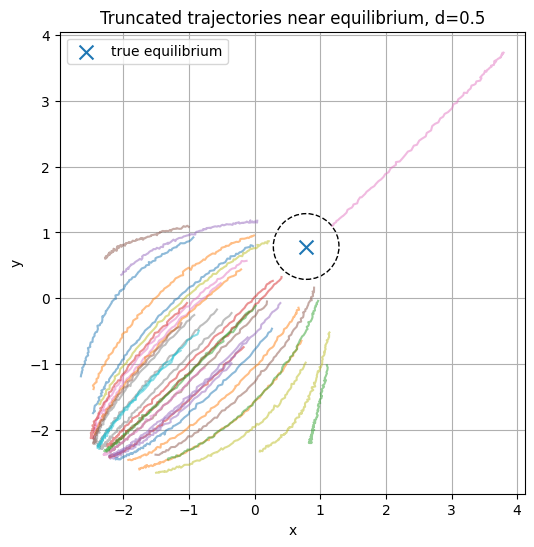

In [20]:
eq_true = torch.tensor([math.pi/4, math.pi/4], dtype=torch.float32, device=device)
d = 0.5

Z_cut = truncate_near_equilibrium(Z_all, eq_true, d)

plt.figure(figsize=(6, 6))
for i in range(40):
    traj = Z_cut[i].detach().cpu().numpy()
    plt.plot(traj[:, 0], traj[:, 1], alpha=0.5)

plt.scatter(eq_true[0].item(), eq_true[1].item(), s=100, marker='x', label='true equilibrium')
circle = plt.Circle((eq_true[0].item(), eq_true[1].item()), d, fill=False, linestyle='--')
plt.gca().add_patch(circle)

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Truncated trajectories near equilibrium, d={d}")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()

In [21]:
N = z0_all.size(0)
perm = torch.randperm(N)

train_idx = perm[:int(0.8*N)]
test_idx  = perm[int(0.8*N):]

z0_train, z0_test = z0_all[train_idx], z0_all[test_idx]
Z_train_cut, Z_test_cut = Z_cut[train_idx], Z_cut[test_idx]

train_loader_cut = DataLoader(
    TensorDataset(z0_train, Z_train_cut),
    batch_size=64,
    shuffle=True
)

test_loader_cut = DataLoader(
    TensorDataset(z0_test, Z_test_cut),
    batch_size=128,
    shuffle=False
)

In [22]:
class ODEmodel(nn.Module):
    def __init__(self, state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim + (1 if time_dependent else 0)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden, state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, t, z):
        if z.dim() == 1:
            z = z.unsqueeze(0)

        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z

        return self.net(h)


class NeuralODE(nn.Module):
    def __init__(self, func, use_adjoint=True, rtol=1e-3, atol=1e-4, method="dopri5"):
        super().__init__()
        self.func = func
        self.use_adjoint = use_adjoint
        self.rtol = rtol
        self.atol = atol
        self.method = method

    def forward(self, z0, t):
        solver = odeint_adjoint if self.use_adjoint else odeint
        Z = solver(self.func, z0, t, rtol=self.rtol, atol=self.atol, method=self.method)
        return Z.transpose(0, 1).contiguous()

In [23]:
def mse(z_hat, z_true):
    return torch.mean((z_hat - z_true) ** 2)


def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0

    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            mse_sum += mse(Z_pred, Z).item() * z0.size(0)
            count += z0.size(0)

    return mse_sum / count


def train(model, train_loader, test_loader, t_eval, epochs=300, lr=1e-2, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []

    for ep in range(1, epochs + 1):
        model.train()

        for z0, Z in train_loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()

            if clip_grad is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)

            optim.step()

        tr = evaluate(model, train_loader, t_eval)
        te = evaluate(model, test_loader, t_eval)

        train_losses.append(tr)
        test_losses.append(te)

        if ep % 20 == 0:
            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")

    return model, train_losses, test_losses

In [24]:
func_cut = ODEmodel(hidden=64, time_dependent=True).to(device)
node_cut = NeuralODE(func_cut, use_adjoint=True).to(device)

node_cut, train_losses_cut, test_losses_cut = train(
    node_cut,
    train_loader_cut,
    test_loader_cut,
    t_eval,
    epochs=300,
    lr=1e-2,
    tag=f"TRUNC_d={d}"
)

/tmp/ipykernel_18395/2465494982.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)


[TRUNC_d=0.5] Epoch 020 | train 0.184895 | test 0.165959
[TRUNC_d=0.5] Epoch 040 | train 0.105417 | test 0.130051
[TRUNC_d=0.5] Epoch 060 | train 0.088471 | test 0.117779
[TRUNC_d=0.5] Epoch 080 | train 0.060590 | test 0.095905
[TRUNC_d=0.5] Epoch 100 | train 0.048531 | test 0.083470
[TRUNC_d=0.5] Epoch 120 | train 0.044266 | test 0.087824
[TRUNC_d=0.5] Epoch 140 | train 0.025507 | test 0.047920
[TRUNC_d=0.5] Epoch 160 | train 0.026374 | test 0.062656
[TRUNC_d=0.5] Epoch 180 | train 0.024686 | test 0.055635
[TRUNC_d=0.5] Epoch 200 | train 0.020848 | test 0.043592
[TRUNC_d=0.5] Epoch 220 | train 0.020323 | test 0.046936
[TRUNC_d=0.5] Epoch 240 | train 0.023972 | test 0.046601
[TRUNC_d=0.5] Epoch 260 | train 0.022423 | test 0.053752
[TRUNC_d=0.5] Epoch 280 | train 0.020478 | test 0.054294
[TRUNC_d=0.5] Epoch 300 | train 0.019282 | test 0.043898


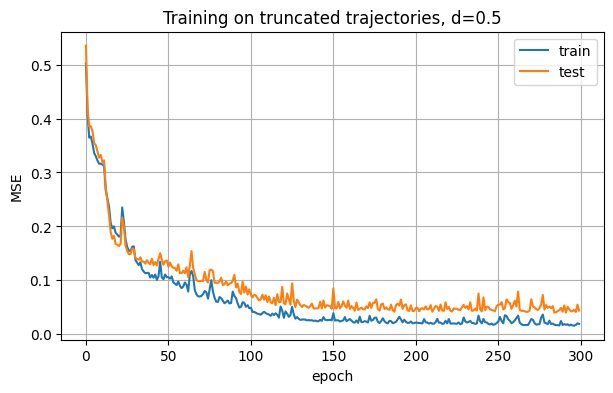

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(train_losses_cut, label="train")
plt.plot(test_losses_cut, label="test")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title(f"Training on truncated trajectories, d={d}")
plt.grid(True)
plt.legend()
plt.show()

In [27]:
def find_equilibrium(func, x0, t0=0.0, steps=2500, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v ** 2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()

    return x.detach(), res

In [28]:
x0 = torch.tensor([0.6, 0.6], dtype=torch.float32, device=device)
eq_pred, res = find_equilibrium(node_cut.func, x0)

print("True equilibrium :", eq_true.detach().cpu().numpy())
print("Pred equilibrium :", eq_pred.detach().cpu().numpy())
print("Residual         :", res)
print("Distance error   :", torch.norm(eq_pred - eq_true).item())

True equilibrium : [0.7853982 0.7853982]
Pred equilibrium : [0.9364976  0.44325075]
Residual         : 1.5389327927550767e-06
Distance error   : 0.3740266263484955
